In [292]:
import pandas as pd
import numpy as np
import seaborn as sns
import statsmodels.formula.api as smf

df = pd.read_stata('Integration.dta')
df.columns

Index(['id', 'mand', 'ankomstaar', 'alder', 'aarslon', 'aar'], dtype='object')

In [293]:
#Problem 1: 
#1.A: deskriptiv analyse
df['kohorte14'] = (df.ankomstaar == 2014)
df['kohorte15'] = (df.ankomstaar == 2015)
df['kohorte16'] = (df.ankomstaar == 2016)

table1 = (
    df.groupby(['aar', 'mand'])
    [['aarslon', 'alder', 'kohorte14', 'kohorte15', 'kohorte16']]
    .mean()
    .round(2)
)

print('Table 1:')
print(table1)

Table 1:
                  aarslon      alder  kohorte14  kohorte15  kohorte16
aar    mand                                                          
2017.0 0.0   31124.439453  28.629999       0.34       0.34       0.32
       1.0   61324.039062  28.670000       0.33       0.32       0.35
2018.0 0.0   40045.050781  29.629999       0.34       0.34       0.32
       1.0   90906.500000  29.670000       0.33       0.32       0.35


In [294]:
#1.B
df['log_loen'] = np.log(df['aarslon'])
df['YSM'] = df['aar'] - df['ankomstaar']

df2017 = df[df['aar'] == 2017]

results = smf.ols('log_loen ~ alder + YSM', data=df2017).fit()

print('Table 2:')
print(results.summary())


Table 2:
                            OLS Regression Results                            
Dep. Variable:               log_loen   R-squared:                       0.032
Model:                            OLS   Adj. R-squared:                  0.031
Method:                 Least Squares   F-statistic:                     39.84
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           9.53e-18
Time:                        13:38:00   Log-Likelihood:                -1639.8
No. Observations:                2400   AIC:                             3286.
Df Residuals:                    2397   BIC:                             3303.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     10.4231      0.047    219.799

In [295]:
#1.C
df2017['alderminusYSM'] = df2017['alder'] - df2017['YSM']

results = smf.ols('log_loen ~ alderminusYSM + YSM', data = df2017).fit()
print('Table 3:')
print(results.summary())

Table 3:
                            OLS Regression Results                            
Dep. Variable:               log_loen   R-squared:                       0.032
Model:                            OLS   Adj. R-squared:                  0.031
Method:                 Least Squares   F-statistic:                     39.84
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           9.53e-18
Time:                        13:38:00   Log-Likelihood:                -1639.8
No. Observations:                2400   AIC:                             3286.
Df Residuals:                    2397   BIC:                             3303.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        10.4231      0.047  

/var/folders/h7/g3f7rz653qj6s7z5mrzdz2g40000gn/T/ipykernel_43940/414851763.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2017['alderminusYSM'] = df2017['alder'] - df2017['YSM']


In [296]:
#Problem 2
results = smf.ols('log_loen ~ alder + YSM + ankomstaar', data = df).fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:               log_loen   R-squared:                       0.073
Model:                            OLS   Adj. R-squared:                  0.072
Method:                 Least Squares   F-statistic:                     125.4
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           3.61e-78
Time:                        13:38:00   Log-Likelihood:                -4102.0
No. Observations:                4800   AIC:                             8212.
Df Residuals:                    4796   BIC:                             8238.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -457.8689     38.818    -11.795      0.0

In [297]:
#Problem 3
#3.A
df['alder2'] = df.alder ** 2
df['YSM2'] = df.YSM ** 2

results = smf.ols('log_loen ~ alder + alder2 + YSM + YSM2 + kohorte15 + kohorte16', data = df).fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:               log_loen   R-squared:                       0.125
Model:                            OLS   Adj. R-squared:                  0.124
Method:                 Least Squares   F-statistic:                     114.6
Date:                Thu, 15 Oct 2026   Prob (F-statistic):          1.48e-135
Time:                        13:38:00   Log-Likelihood:                -3961.5
No. Observations:                4800   AIC:                             7937.
Df Residuals:                    4793   BIC:                             7982.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             8.0633      0.12

In [298]:
#3.B

# i) Hypotesetest
# Urestrikteret model
urestrikteret = results

# Restrikteret model
df['lin_kohorte'] = df['kohorte15'] + 2*df['kohorte16']
restrikteret = smf.ols('log_loen ~ alder + YSM + lin_kohorte', data = df).fit()

# F-test
RSSur = urestrikteret.ssr
RSSr = restrikteret.ssr

q = 3
n = len(df)
k_ur = 7

F_stat = ((RSSr - RSSur)/q) / (RSSur/(n - k_ur))

from scipy import stats

p = 1 - stats.f.cdf(F_stat, q, n - k_ur)
print(f'i)')
print(f' F_stat = {F_stat:.4f}')
print(f' p = {p:.4f}')

# ii)

# Urestrikteret model
df_m = df[df['mand'] == 1]
df_k = df[df['mand'] == 0]

model_mand = smf.ols('log_loen ~ alder + alder2 + YSM + YSM2 + kohorte15 + kohorte16', data=df_m ).fit()
model_kvinde = smf.ols('log_loen ~ alder + alder2 + YSM + YSM2 + kohorte15 + kohorte16', data=df_k).fit()

# Restrikteret model
restrikteret = results

# F-test
RSSr = restrikteret.ssr
RSSur = model_mand.ssr + model_kvinde.ssr

q = 7
n = len(df)
k_ur = 14

F_stat = ((RSSr - RSSur) / q) / (RSSur / (n - k_ur))

p = 1 - stats.f.cdf(F_stat, q, n - k_ur)
print(f'ii)')
print(f' F_stat = {F_stat:.4f}')
print(f' p = {p:.4f}')

i)
 F_stat = 96.3058
 p = 0.0000
ii)
 F_stat = 321.4585
 p = 0.0000


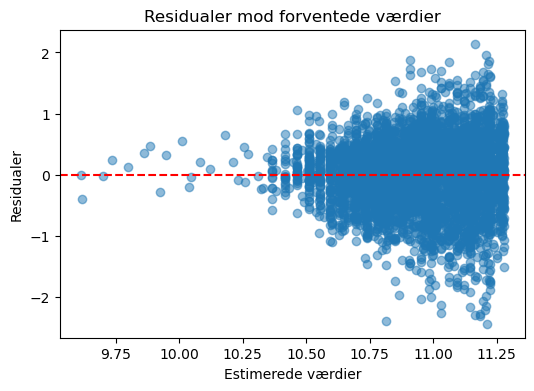

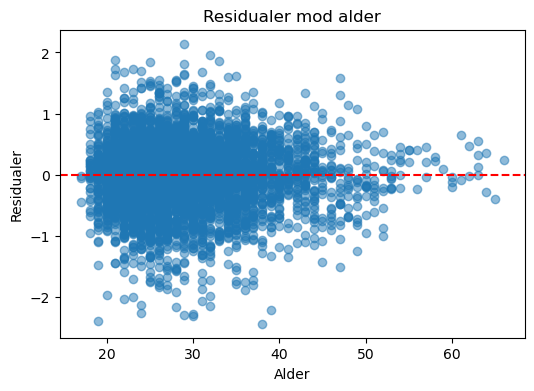

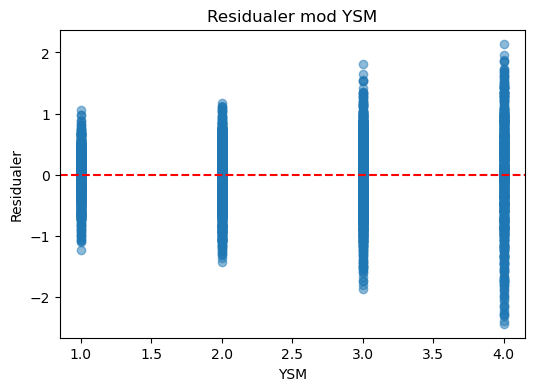

Breusch-Pagan LM: 576.2132
Breusch-Pagan p: 0.0000


In [299]:
# 3.C Heteroskedasticitet

import matplotlib.pyplot as plt
from statsmodels.stats.diagnostic import het_breuschpagan

# Brug den urestrikterede model fra 3(a)
residualer = results.resid
forventede = results.fittedvalues

# Residualplot mod forventede værdier
plt.figure(figsize=(6,4))
plt.scatter(forventede, residualer, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Estimerede værdier')
plt.ylabel('Residualer')
plt.title('Residualer mod forventede værdier')
plt.show()

# Residualplot mod alder
plt.figure(figsize=(6,4))
plt.scatter(df['alder'], residualer, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Alder')
plt.ylabel('Residualer')
plt.title('Residualer mod alder')
plt.show()

# Residualplot mod YSM
plt.figure(figsize=(6,4))
plt.scatter(df['YSM'], residualer, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('YSM')
plt.ylabel('Residualer')
plt.title('Residualer mod YSM')
plt.show()

# Breusch-Pagan test
bp_test = het_breuschpagan(residualer, results.model.exog)

LM = bp_test[0]
p = bp_test[1]

print(f"Breusch-Pagan LM: {LM:.4f}")
print(f"Breusch-Pagan p: {p:.4f}")

In [300]:
# Problem 5 : generel kode til alle delopgaver

import statsmodels.api as sm


# Generel simulationsfunktion til 5A, 5B og 5C
def simulate(n):
    beta0 = 2
    beta1 = 3
    beta2 = -1
    beta3 = -1

    # x_j ~ N(1,4), så standardafvigelsen er 2
    x1 = np.random.normal(loc=1, scale=2, size=n)
    x2 = np.random.normal(loc=1, scale=2, size=n)
    x3 = np.random.normal(loc=1, scale=2, size=n)

    # Var(epsilon_i | X) = 1/4 * x1_i^4
    # Standardafvigelsen er derfor 1/2 * x1_i^2
    sigma_epsilon = 0.5 * x1**2
    epsilon = np.random.normal(
        loc=0,
        scale=sigma_epsilon,
        size=n
    )

    y = beta0 + beta1*x1 + beta2*x2 + beta3*x3 + epsilon

    X = pd.DataFrame({
        'x1': x1,
        'x2': x2,
        'x3': x3
    })

    X = sm.add_constant(X)

    # OLS med almindelige standardfejl
    model_ols = sm.OLS(y, X)
    results_ols = model_ols.fit()

    # Samme OLS-estimat med HC1-robuste standardfejl
    results_robust = model_ols.fit(cov_type='HC1')

    beta1_ols = results_ols.params['x1']
    se_ols = results_ols.bse['x1']
    se_robust = results_robust.bse['x1']

    t_ols = (beta1_ols - beta1) / se_ols
    t_robust = (beta1_ols - beta1) / se_robust

    reject_ols = int(abs(t_ols) > 1.96)
    reject_robust = int(abs(t_robust) > 1.96)

    # WLS med inverse variansvægte
    weights = 4 / x1**4

    model_wls = sm.WLS(y, X, weights=weights)
    results_wls = model_wls.fit()

    beta1_wls = results_wls.params['x1']
    se_wls = results_wls.bse['x1']

    t_wls = (beta1_wls - beta1) / se_wls
    reject_wls = int(abs(t_wls) > 1.96)

    return {
        'beta1_OLS': beta1_ols,
        'se_OLS': se_ols,
        'se_robust': se_robust,
        'reject_OLS': reject_ols,
        'reject_robust': reject_robust,
        'beta1_WLS': beta1_wls,
        'se_WLS': se_wls,
        'reject_WLS': reject_wls
    }


def monte_carlo(reps, n):
    np.random.seed(0)

    simulationer = []

    for rep in range(reps):
        resultat = simulate(n)
        simulationer.append(resultat)

    return pd.DataFrame(simulationer)


results_1000 = monte_carlo(reps=1000, n=1000)
results_50 = monte_carlo(reps=1000, n=50)

def make_ols_table(results):
    return pd.DataFrame({
        'OLS-standardfejl': [
            results['beta1_OLS'].mean(),
            results['beta1_OLS'].std(),
            results['se_OLS'].mean(),
            results['se_OLS'].std(),
            results['reject_OLS'].mean()
        ],

        'Robuste standardfejl': [
            results['beta1_OLS'].mean(),
            results['beta1_OLS'].std(),
            results['se_robust'].mean(),
            results['se_robust'].std(),
            results['reject_robust'].mean()
        ]
    }, index=[
        'Middelværdi af beta1_hat',
        'Standardafvigelse af beta1_hat',
        'Middelværdi af standardfejl',
        'Standardafvigelse af standardfejl',
        'Andel forkastelser af H0'
    ])

In [301]:
#5. A
print("5A: n = 1000")
print(make_ols_table(results_1000).round(4))

5A: n = 1000
                                   OLS-standardfejl  Robuste standardfejl
Middelværdi af beta1_hat                     3.0017                3.0017
Standardafvigelse af beta1_hat               0.1362                0.1362
Middelværdi af standardfejl                  0.0672                0.1369
Standardafvigelse af standardfejl            0.0054                0.0213
Andel forkastelser af H0                     0.3410                0.0360


In [302]:
#5.B
print("5B: n = 50")
print(make_ols_table(results_50).round(4))

5B: n = 50
                                   OLS-standardfejl  Robuste standardfejl
Middelværdi af beta1_hat                     3.0267                3.0267
Standardafvigelse af beta1_hat               0.5814                0.5814
Middelværdi af standardfejl                  0.2827                0.4887
Standardafvigelse af standardfejl            0.0863                0.2190
Andel forkastelser af H0                     0.3310                0.0740


In [303]:
#5.C
def make_wls_table(results):
    return pd.DataFrame({
        'OLS med robuste SE': [
            results['beta1_OLS'].mean(),
            results['beta1_OLS'].std(),
            results['se_robust'].mean(),
            results['se_robust'].std(),
            results['reject_robust'].mean()
        ],

        'WLS': [
            results['beta1_WLS'].mean(),
            results['beta1_WLS'].std(),
            results['se_WLS'].mean(),
            results['se_WLS'].std(),
            results['reject_WLS'].mean()
        ]
    }, index=[
        'Middelværdi af beta1_hat',
        'Standardafvigelse af beta1_hat',
        'Middelværdi af standardfejl',
        'Standardafvigelse af standardfejl',
        'Andel forkastelser af H0'
    ])

print("5C: n = 50")
print(make_wls_table(results_50).round(4))

print("\n5C: n = 1000")
print(make_wls_table(results_1000).round(4))

5C: n = 50
                                   OLS med robuste SE     WLS
Middelværdi af beta1_hat                       3.0267  3.0000
Standardafvigelse af beta1_hat                 0.5814  0.0532
Middelværdi af standardfejl                    0.4887  0.0485
Standardafvigelse af standardfejl              0.2190  0.0193
Andel forkastelser af H0                       0.0740  0.0590

5C: n = 1000
                                   OLS med robuste SE     WLS
Middelværdi af beta1_hat                       3.0017  3.0000
Standardafvigelse af beta1_hat                 0.1362  0.0025
Middelværdi af standardfejl                    0.1369  0.0024
Standardafvigelse af standardfejl              0.0213  0.0008
Andel forkastelser af H0                       0.0360  0.0540
